In [1]:
import numpy
import pandas
import seaborn

from matplotlib import pyplot

from fitting import TIMESERIES_TABLE_PATH
from realistic import PARAMS

/Users/adam/.local/share/virtualenvs/src-VJqicAka/lib/python3.11/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/adam/.local/share/virtualenvs/src-VJqicAka/lib/python3.11/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/adam/.local/share/virtualenvs/src-VJqicAka/lib/python3.11/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 366 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


In [2]:
pyplot.rcParams["figure.figsize"] = [12.8, 9.6]

In [3]:
def err(obs, model):
    scale = numpy.abs(obs)
    scale[scale == 0] = 1
    return numpy.abs(obs - model) / scale

In [4]:
params = {
    'a': 'fitted_a',
    'b': 'fitted_b',
    'e': 'fitted_e',
    'periapsis_phase': 'fitted_periapsis_phase',
    'Macc': 'fitted_Macc',
    'Porb': 'fitted_porb',
}

In [5]:
results = pandas.read_pickle(TIMESERIES_TABLE_PATH)

In [6]:
results

,a,e,periapsis_phase,Macc,Porb,tau_eff,Mcomp,Rcomp,b,rv,...,baseline,pristine idx,realistic_idx,fitted_a,fitted_b,fitted_Macc,fitted_e,fitted_periapsis_phase,fitted_porb,fitted_tau_eff
0,0.308884,0,0,10.208333,18.729310,0.077967,1.0,1.0,8.367347,"[269525.2054814849, 107308.73292668686, -44103...",...,1825,11016,2444,0.325615,1.371668,9.016706,0.034821,2.966417,21.443309,0.104268
1,0.232995,0,0,30.000000,7.377989,0.043251,1.0,1.0,5.510204,"[62878.71618068006, 1568194.8365115935, -17739...",...,365,8199,15615,1.629155,0.810149,49.385324,0.701851,3.460237,107.001489,0.138260
2,0.308884,0,0,17.500000,14.578285,0.040673,1.0,1.0,9.387755,"[-895296.612904459, -988685.8203167929, -94785...",...,1825,11140,79744,4.346245,2.406992,50.000000,0.221182,2.922737,463.430502,0.044816
3,0.115140,0,0,9.166667,4.475544,0.057456,1.0,1.0,6.938776,"[-818015.0524311854, -598098.6782656942, -2716...",...,1095,2104,49999,3.144005,0.543618,39.491748,0.359913,3.478722,319.992591,0.228676
4,65.512856,0,0,6.041667,72987.836649,2.996957,1.0,1.0,0.408163,"[472.06486625793485, 806.7905757377384, 1132.1...",...,1825,32689,14363,0.634299,2.160915,0.527037,0.908992,5.929848,149.318912,0.351062
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3395,0.308884,0,0,10.208333,18.729310,0.075858,1.0,1.0,8.775510,"[269503.1454238444, 176981.63181511706, 79610....",...,1095,11066,77197,0.449684,5.819793,3.954527,0.390010,1.260754,49.483284,0.164379
3396,0.471487,0,0,19.583333,26.064215,0.081657,1.0,1.0,4.081633,"[865471.3880916121, 680284.544844101, -77075.7...",...,1825,14057,48188,0.362869,3.256686,8.367878,0.731621,5.968439,26.085746,0.109734
3397,0.132571,0,0,16.458333,4.219592,0.049643,1.0,1.0,2.244898,"[-1395284.4040855, -1146487.413598774]",...,365,2786,19173,1.805113,0.879524,42.698617,0.745124,3.191261,134.005059,0.157137
3398,0.828643,0,0,9.166667,86.409234,0.172380,1.0,1.0,0.408163,"[48877.424784341274, -297319.05924287904, 2928...",...,1095,17798,52599,0.828642,0.709928,9.166591,0.000243,0.219630,86.409365,0.172054


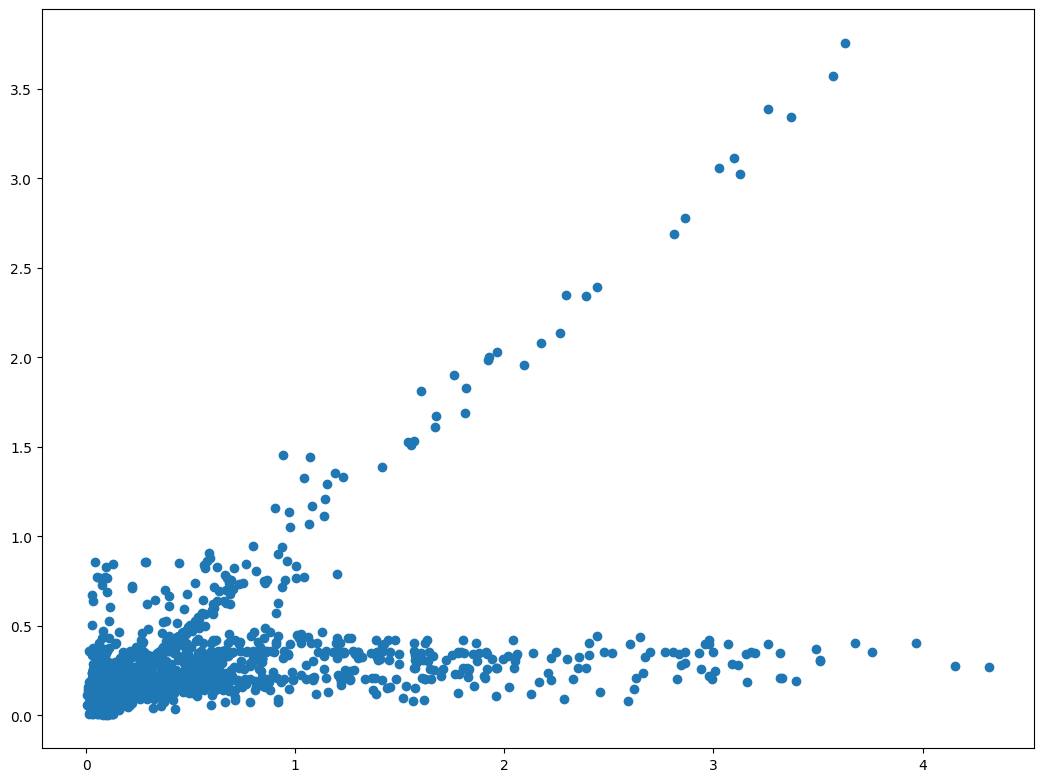

In [7]:
pyplot.scatter(results['tau_eff'], results['fitted_tau_eff'])

In [8]:
# for a, b in params:
#     results[f'{a} err'] = numpy.log10(numpy.abs(results[b] - results[a]))

In [9]:
# results['close'] = (
#     numpy.isclose(results['a'], results['fitted_a'], rtol=1)
#     & numpy.isclose(results['Macc'], results['fitted_Macc'], rtol=1)
#     # & numpy.isclose(results['Porb'], results['fitted_porb'], rtol=0.1)
# )
# results['close'].value_counts()

In [10]:
# results[['a', 'b', 'fitted_a', 'Macc', 'fitted_Macc', 'Porb', 'fitted_porb', 'close']]

In [11]:
# # a = seaborn.swarmplot(data=results, x='baseline', y='Porb', hue='close', col='cadence')
# a = seaborn.catplot(
#     data=results, kind="strip",
#     x='baseline', y='Porb', hue='Porb err', col='cadence',
#     aspect=.5, jitter=True,
# )
# pyplot.yscale('log')
# seaborn.move_legend(a, "upper left", bbox_to_anchor=(1, 1))

In [12]:
# # a = seaborn.swarmplot(data=results, x='baseline', y='Porb', hue='close', col='cadence')
# a = seaborn.catplot(
#     data=results, kind="strip",
#     x='baseline', y='Macc', hue='Macc err', col='cadence',
#     aspect=.5, jitter=True,
# )
# seaborn.move_legend(a, "upper left", bbox_to_anchor=(1, 1))

In [13]:
# # a = seaborn.swarmplot(data=results, x='baseline', y='Porb', hue='close', col='cadence')
# a = seaborn.catplot(
#     data=results, kind="strip",
#     x='baseline', y='a', hue='a err', col='cadence',
#     aspect=.5, jitter=True,
# )
# seaborn.move_legend(a, "upper left", bbox_to_anchor=(1, 1))
# pyplot.yscale('log')

In [14]:
# # Scatter plot version
# def plot_relation(x, y='RV accuracy', logx=True, logy=True):
#     for cadence, cadence_group in results.groupby('cadence'):
#         baselines = cadence_group['baseline'].unique()
#         baselines = numpy.sort(baselines)
#         fig, axes = pyplot.subplots(1, len(baselines), figsize=(6 * len(baselines), 5), sharey=True)
#         if len(baselines) == 1:
#             axes = [axes]
#         for ax, baseline in zip(axes, baselines):
#             subset = cadence_group[cadence_group['baseline'] == baseline]
#             ax.set_title(f'Cadence: {cadence}, Baseline: {baseline}')
#             ax.set_xlabel(x)
#             ax.set_ylabel(y)
#             if logx:
#                 ax.set_xscale('log')
#             if logy:
#                 ax.set_yscale('log')
#             colors = subset['close'].map({True: 'tab:blue', False: 'tab:red'})
#             ax.scatter(subset[x], subset[y], c=colors, alpha=0.7, s=4, label=None)
#             handles = [
#                 pyplot.Line2D([0], [0], marker='o', color='w', label='close', markerfacecolor='tab:blue', markersize=8),
#                 pyplot.Line2D([0], [0], marker='o', color='w', label='not close', markerfacecolor='tab:red', markersize=8)
#             ]
#             if ax == axes[0]:
#                 ax.legend(handles=handles, title='close')
#             else:
#                 ax.legend_.remove() if hasattr(ax, 'legend_') and ax.legend_ else None
#         pyplot.tight_layout()
#         pyplot.show()

In [15]:
def plot_relation(x, y='RV accuracy', logx=True, logy=True, bins=20):
    for cadence, cadence_group in results.groupby('cadence'):
        baselines = numpy.sort(cadence_group['baseline'].unique())
        fig, axes = pyplot.subplots(1, len(baselines), figsize=(6 * len(baselines), 5), sharey=True)
        if len(baselines) == 1:
            axes = [axes]
        for ax, baseline in zip(axes, baselines):
            subset = cadence_group[cadence_group['baseline'] == baseline]
            close =  numpy.isclose(subset[x], subset[params[x]], rtol=0.1)
            # Bin the data
            xdata = subset[x]
            ydata = subset[y]
            if logx:
                xbins = numpy.logspace(numpy.log10(xdata.min()), numpy.log10(xdata.max()), bins + 1)
            else:
                xbins = numpy.linspace(xdata.min(), xdata.max(), bins + 1)
            if logy:
                ybins = numpy.logspace(numpy.log10(ydata.min()), numpy.log10(ydata.max()), bins + 1)
            else:
                ybins = numpy.linspace(ydata.min(), ydata.max(), bins + 1)
            # 2D histogram for "close" fraction
            hist_total, _, _ = numpy.histogram2d(xdata, ydata, bins=[xbins, ybins])
            hist_close, _, _ = numpy.histogram2d(xdata[close], ydata[close], bins=[xbins, ybins])
            # Avoid division by zero
            with numpy.errstate(invalid='ignore', divide='ignore'):
                frac_close = hist_close / hist_total
            # Plot
            mesh = ax.pcolormesh(xbins, ybins, frac_close.T, cmap='coolwarm_r', vmin=0, vmax=1)
            ax.set_title(f'Cadence: {cadence}, Baseline: {baseline}')
            ax.set_xlabel(x)
            ax.set_ylabel(y)
            if logx:
                ax.set_xscale('log')
            if logy:
                ax.set_yscale('log')
            fig.colorbar(mesh, ax=ax, label='Fraction close')
        pyplot.tight_layout()
        pyplot.show()

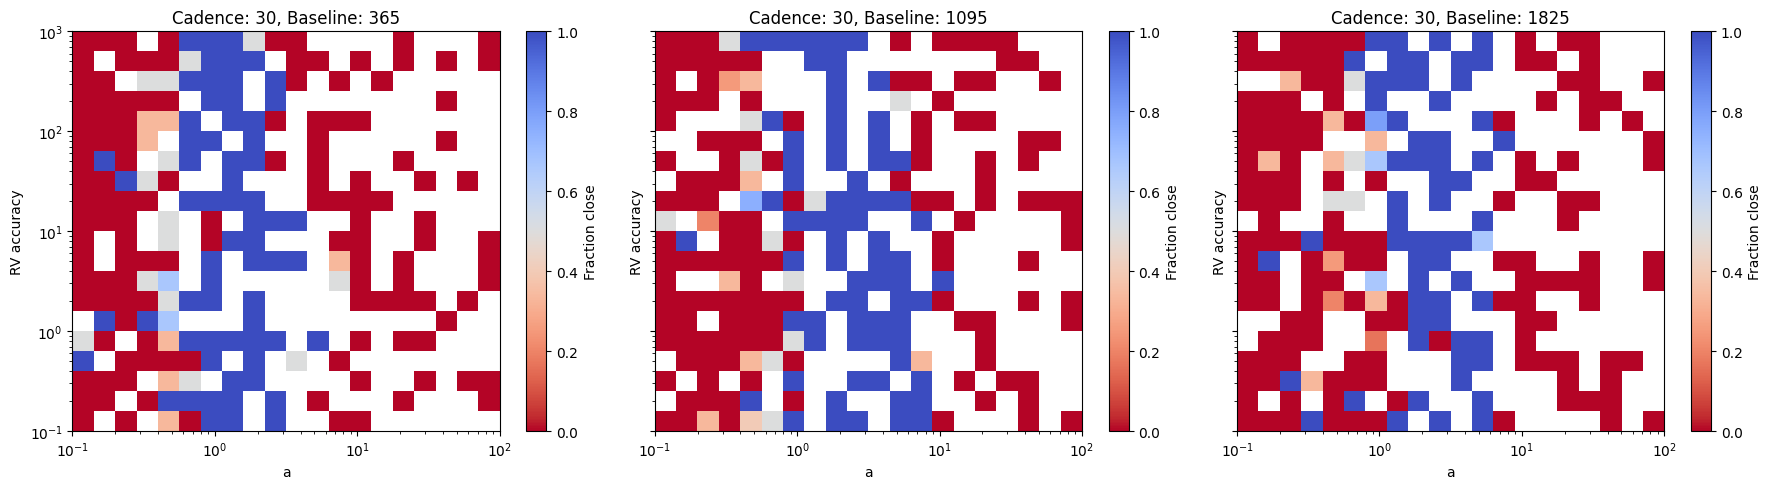

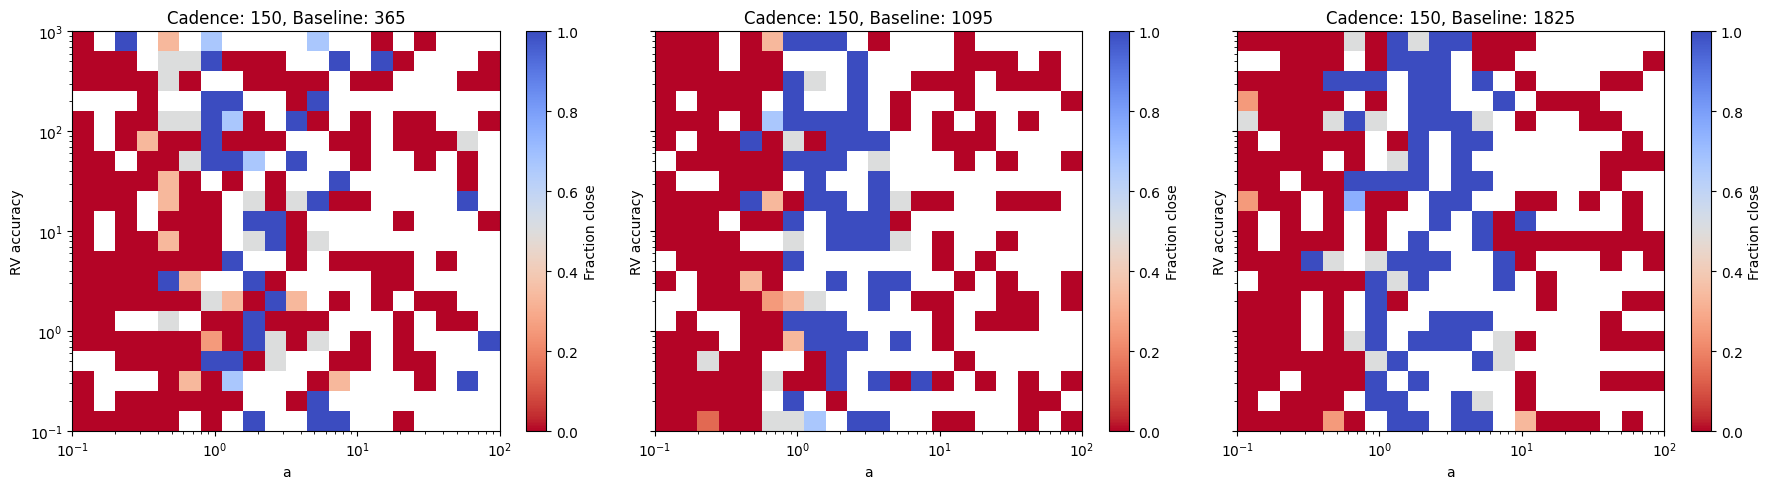

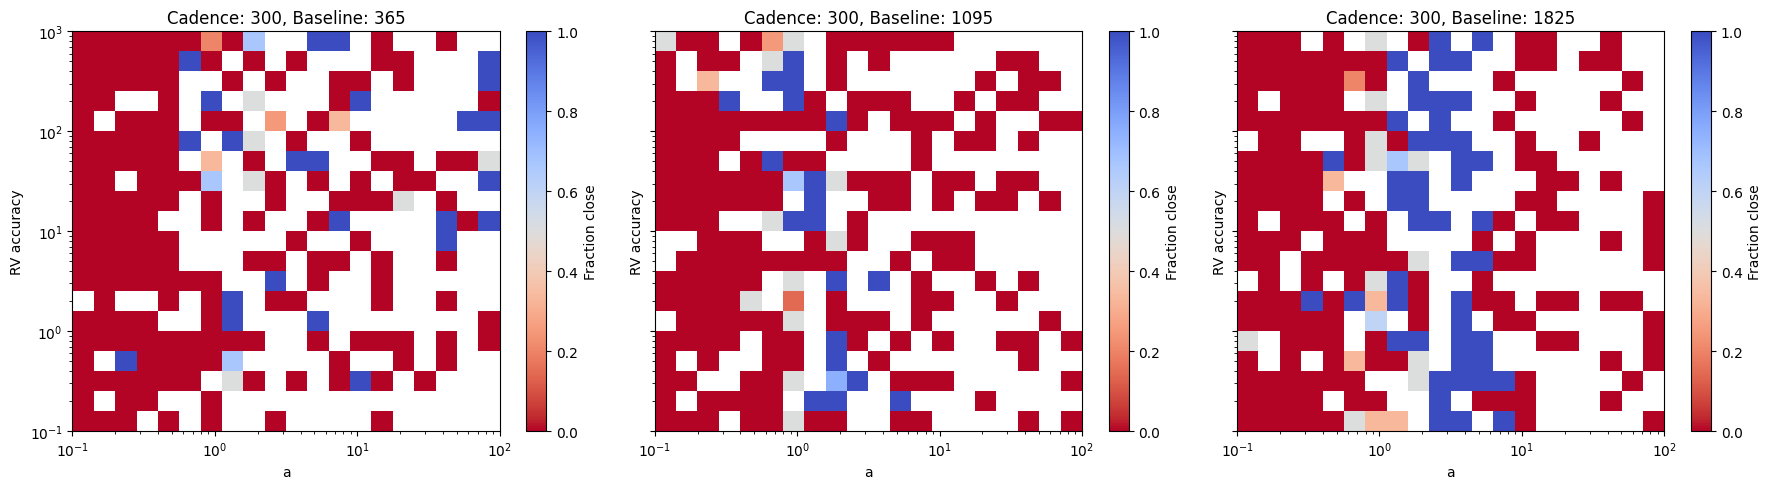

In [16]:
plot_relation('a')

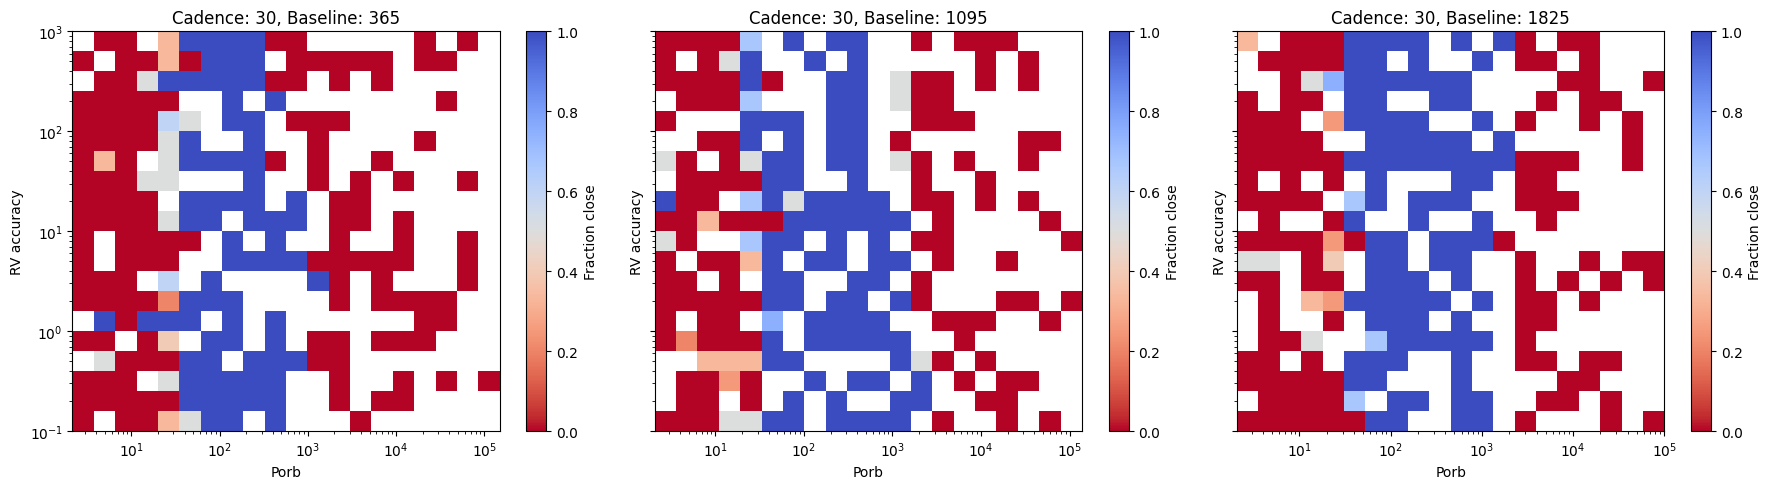

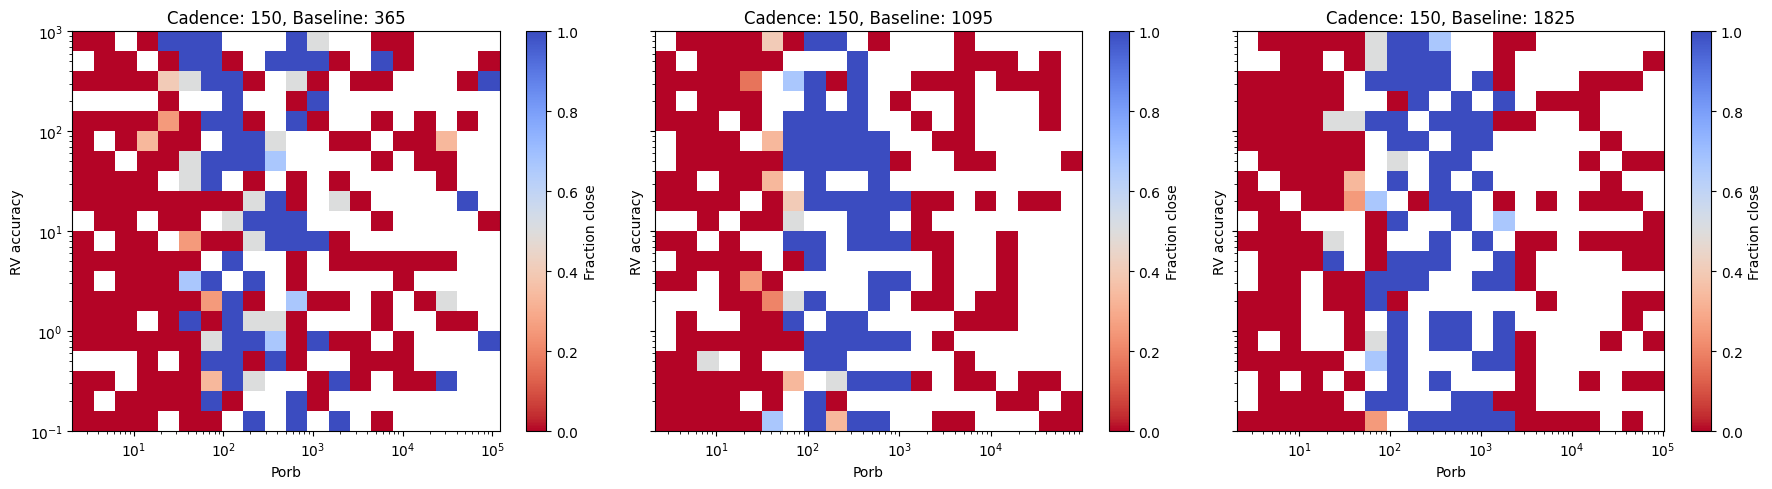

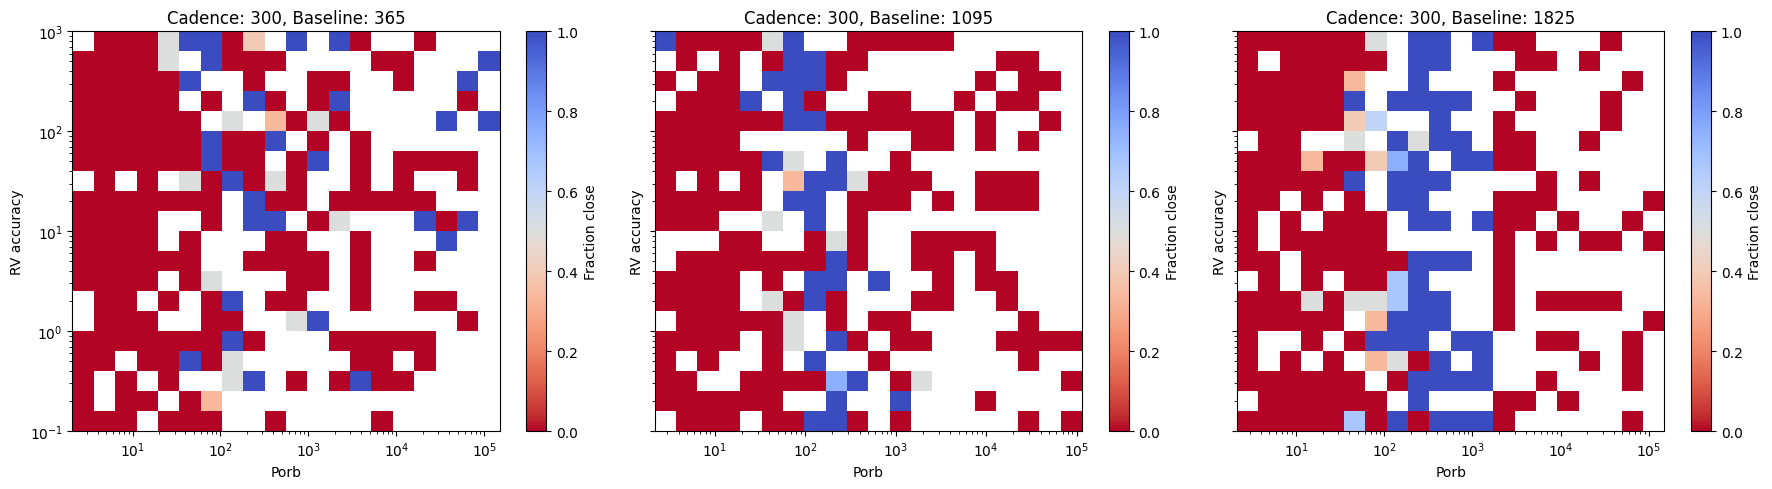

In [17]:
plot_relation('Porb')

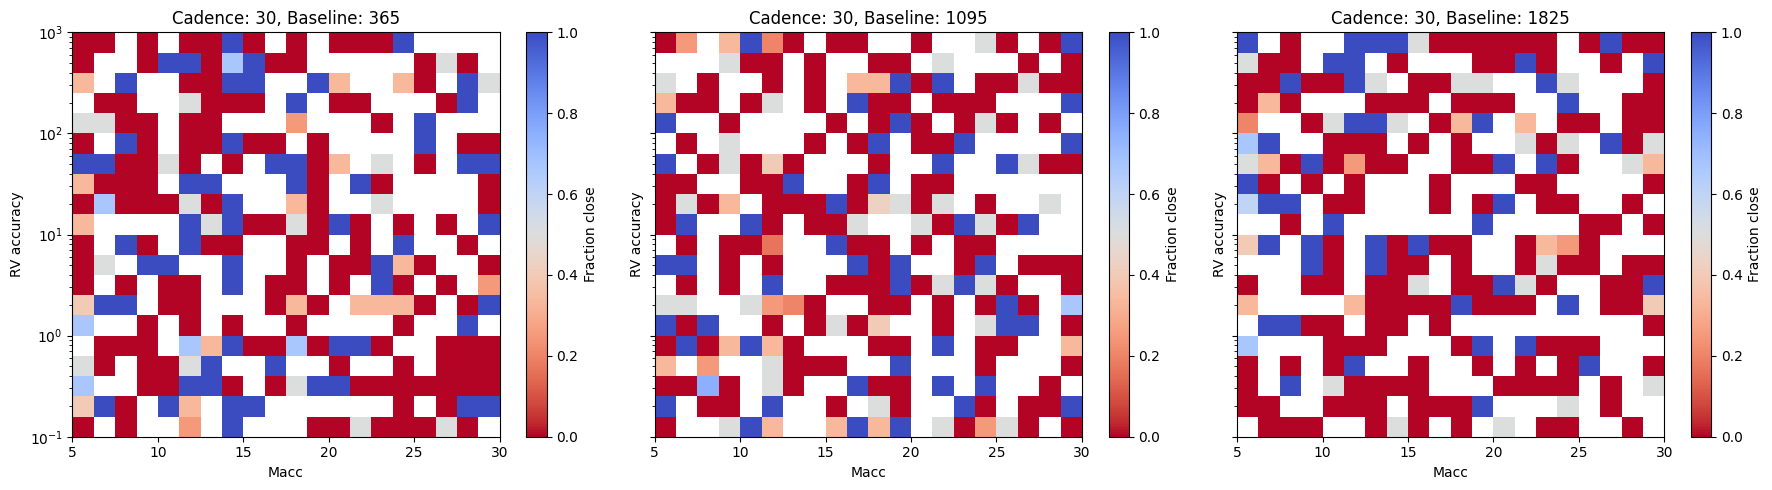

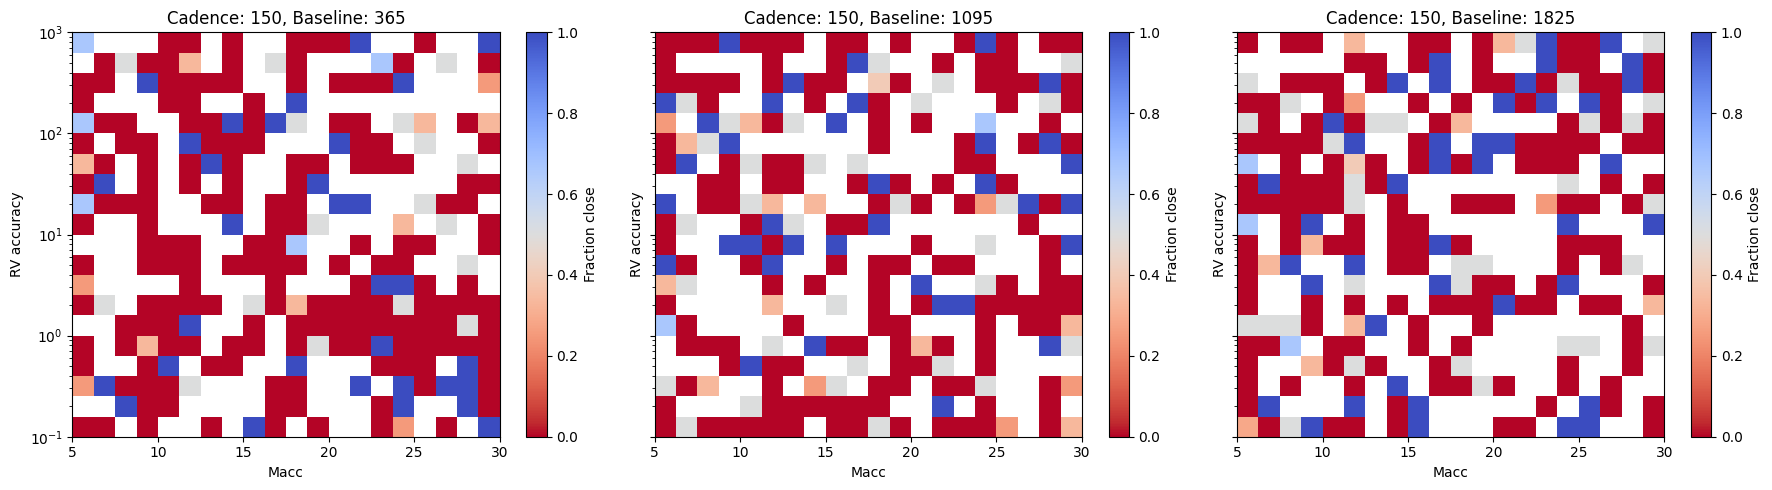

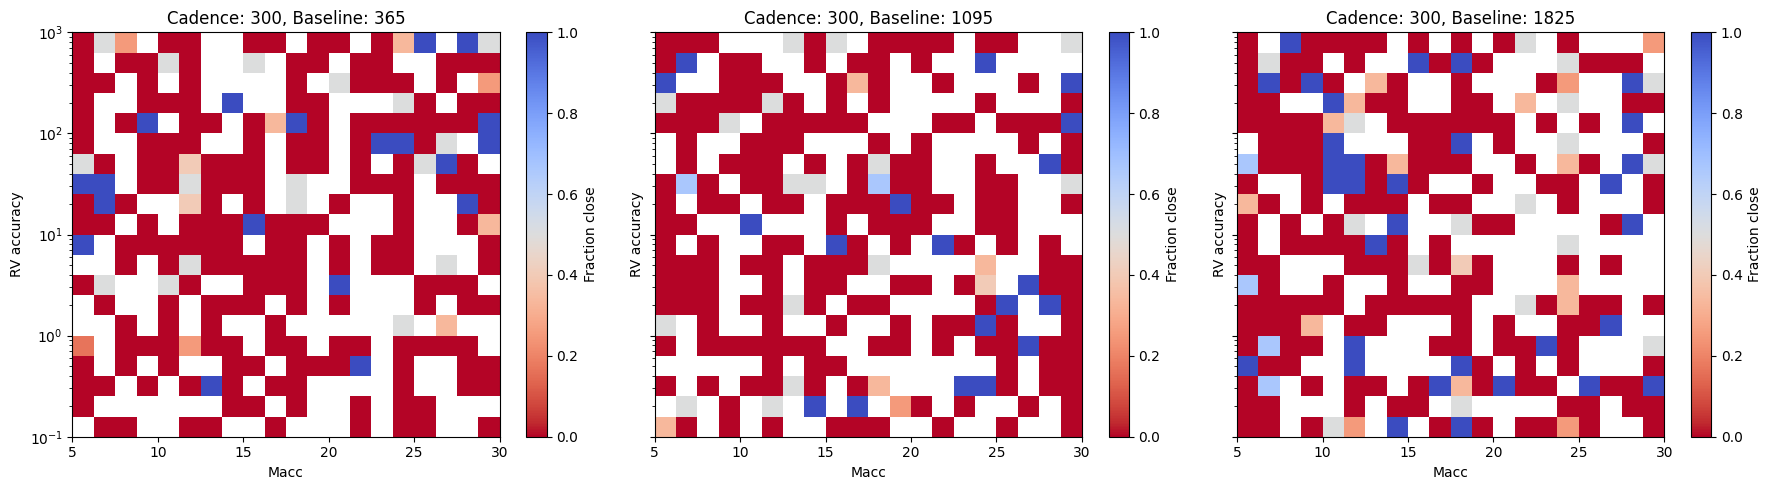

In [18]:
plot_relation('Macc', logx=False)

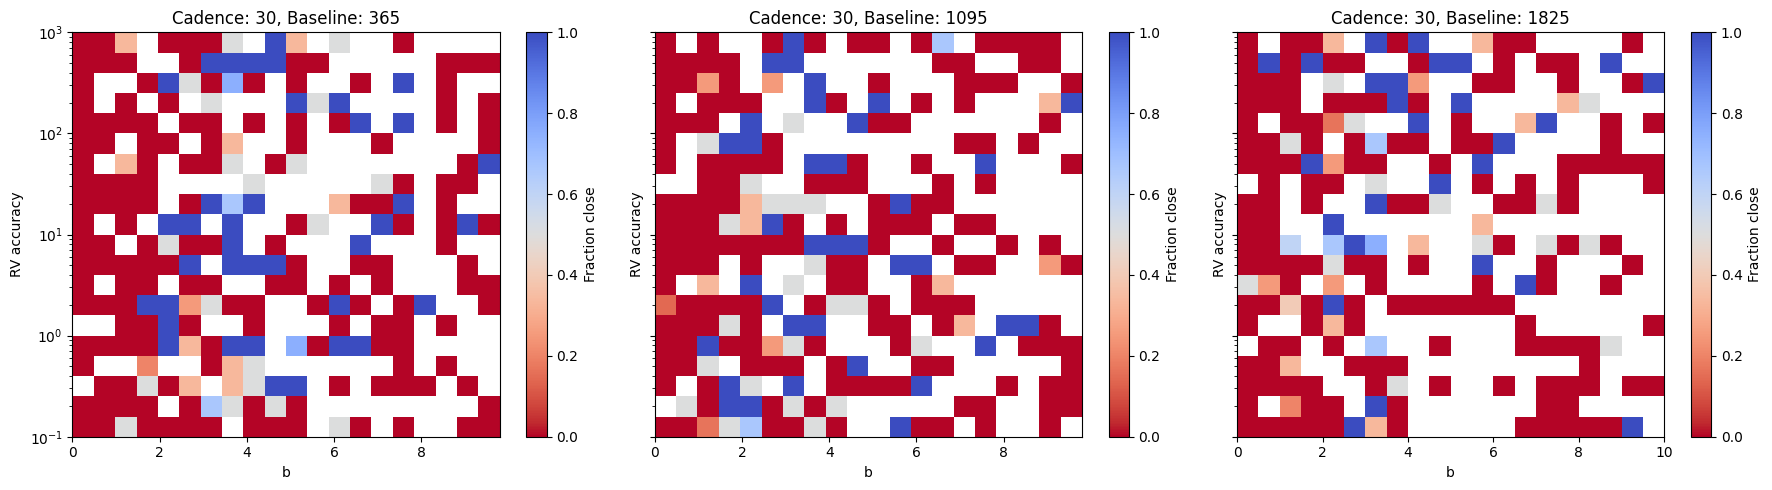

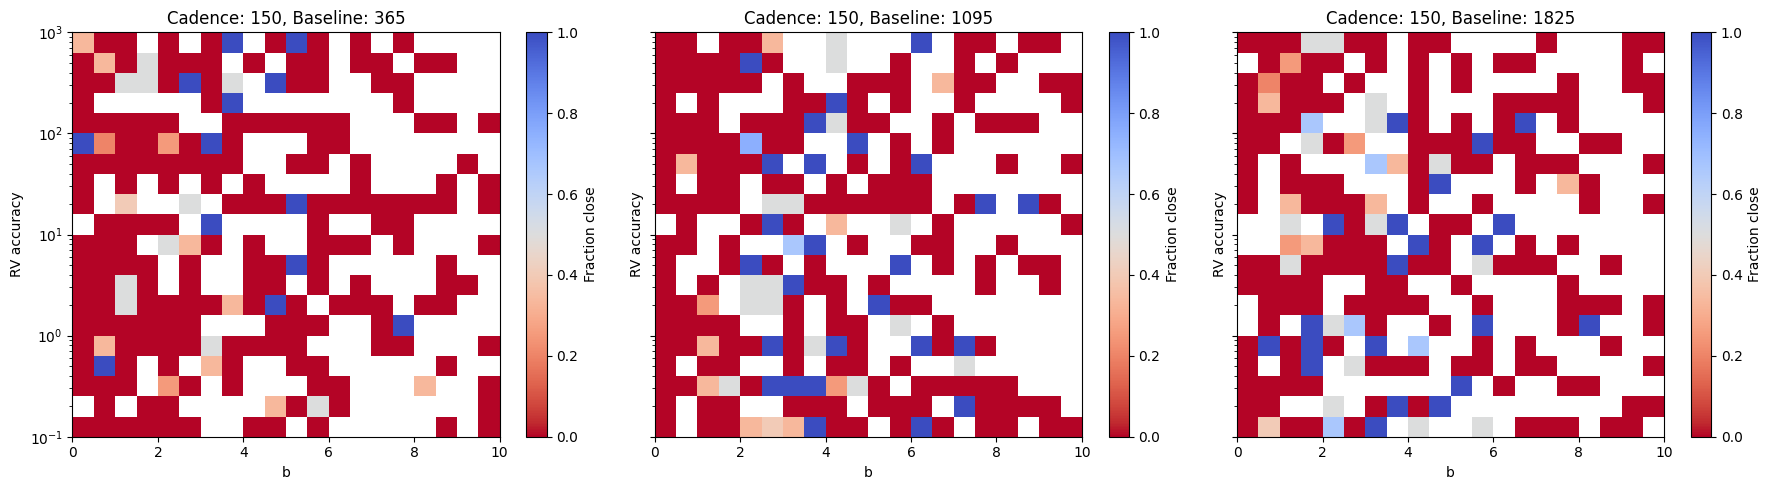

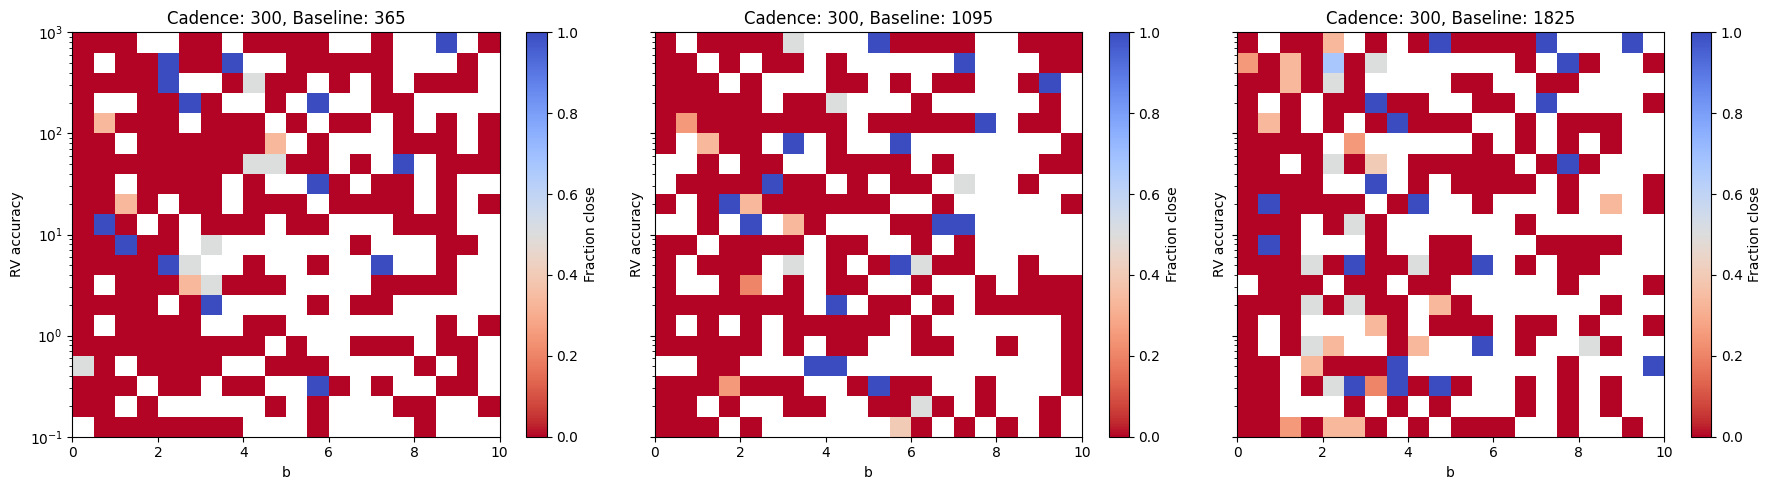

In [19]:
plot_relation('b', logx=False)